# Detección y localización de grietas con mascara


In [3]:
# [SOLO_COLAB]
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os, re, shutil, random
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, precision_score, recall_score,
                             accuracy_score, balanced_accuracy_score, f1_score, fbeta_score,
                             matthews_corrcoef)

# ---------------- Configuración ----------------
RUTA_DRIVE   = Path('/content/drive/MyDrive/IA 2/Dataset_IA2')   # dataset original
RUTA_LOCAL   = Path('/content/dataset')                          # copia local (más rápida que Drive)
RUTA_MODELOS = Path('/content/drive/MyDrive/IA 2/modelos/modelos')       # aquí se guardan los modelos
RUTA_MODELOS.mkdir(parents=True, exist_ok=True)

TAM_IMG  = (256, 256)
TAM_LOTE = 32
SEMILLA  = 123
EPOCAS_FASE1 = 5     # solo cabeza de clasificación
EPOCAS_FASE2 = 10    # fine-tuning
LR_FASE1 = 1e-3
LR_FASE2 = 1e-5

# ---------------- Modo de ejecución (v3) ----------------
#   'entrenar'  : Fase 1 + Fase 2 desde cero (~2 h en la GPU de Colab)
#   'cargar'    : carga el modelo ya entrenado y SOLO re-evalúa y localiza (minutos)
#   'continuar' : carga el modelo y hace una Fase 3 de fine-tuning (más bloques) -> modelo_grietas_v3.keras
MODO           = 'cargar'
ARCHIVO_MODELO = 'modelo_grietas_final.keras'   # modelo que se carga en 'cargar' / 'continuar' (luego puedes poner 'modelo_grietas_v3.keras')
EPOCAS_FASE3   = 12
LR_FASE3       = 1e-5
BLOQUE_FASE3   = 'block_10_expand'               # desde qué bloque se descongela en la Fase 3 (la Fase 2 usó block_13)

# ---------------- Decisión y localización (v3) ----------------
CRITERIO_UMBRAL = 'f2'      # cómo se elige el umbral en validación: 'f1' | 'f2' (prioriza recall) | 'recall' (recall objetivo)
RECALL_OBJETIVO = 0.80      # solo se usa si CRITERIO_UMBRAL = 'recall'
USAR_TTA        = True      # promedia predicciones y Grad-CAM de la imagen original y sus giros
USAR_CRESTAS    = True      # refina la máscara con el mapa de crestas (estructuras oscuras y delgadas)

random.seed(SEMILLA); np.random.seed(SEMILLA); tf.random.set_seed(SEMILLA)

print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs:', gpus)
if not gpus:
    print('⚠️  No hay GPU: el entrenamiento será MUY lento. Activa una GPU en el entorno de ejecución.')

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. Modelo: MobileNetV2 + `GlobalAveragePooling2D` + capa densa

`GlobalAveragePooling2D` conserva la relación entre cada canal del mapa de características y la decisión final,
que es lo que permite calcular el mapa de activación de clase. Las capas de la cabeza tienen nombre fijo
(`gap`, `dropout`, `clasificador`) para poder usarlas luego en Grad-CAM.

> La advertencia sobre `input_shape` y los pesos de 224×224 es normal: la red es totalmente convolucional y funciona con 256×256.

In [10]:
def obtener_base(modelo):
    """Devuelve el sub-modelo MobileNetV2 anidado dentro del modelo completo."""
    return next(l for l in modelo.layers if isinstance(l, keras.Model))

if MODO in ('cargar', 'continuar'):
    ruta_modelo = RUTA_MODELOS / ARCHIVO_MODELO
    if not ruta_modelo.exists():
        raise FileNotFoundError(f'No existe {ruta_modelo}. Ponle MODO = "entrenar" o corrige ARCHIVO_MODELO.')
    modelo = keras.models.load_model(ruta_modelo)
    base = obtener_base(modelo)
    print(f'Modelo cargado desde {ruta_modelo}  (MODO = {MODO!r})')
else:
    print("MODO = 'entrenar': se usa el modelo recién construido arriba.")

Modelo cargado desde /content/drive/MyDrive/IA 2/modelos/modelos/modelo_grietas_final.keras  (MODO = 'cargar')


## 7. Localización con Grad-CAM (v3)

**Base (igual que v2):** el gradiente se calcula respecto al **logit de la clase "grieta"** de la cabeza `clasificador`
(usar el logit evita gradientes nulos por saturación de la sigmoide), en capas de 8×8, 16×16 y 32×32.

**Qué cambió y por qué (a partir de lo que se vio en las imágenes de la v2):**

1. **Solo se dibuja máscara y cajas si P(grieta) ≥ umbral.** El Grad-CAM se normaliza por su propio máximo, así que en una
   imagen sin grieta siempre "resalta algo" y se dibujaban cajas sobre ruido. Ahora el mapa se muestra solo como diagnóstico.
2. **El mapa de 32×32 ya no entra en la fusión.** En las figuras era una nube de puntos de textura, también en imágenes
   con grieta clara. La fusión (media geométrica) usa 8×8 (dónde mirar) y 16×16 (la forma). El de 32×32 se sigue mostrando como referencia.
3. **Refinamiento con crestas** (`USAR_CRESTAS`): el mapa de calor se multiplica por una respuesta *black-hat*, que resalta estructuras
   oscuras y delgadas (lo que es una grieta). El mapa dice *dónde*, la respuesta de crestas dice *qué píxeles*. Así la máscara se
   acerca a la forma de la grieta en vez de ser una mancha. Limitación: asume grietas más oscuras que su entorno.
4. **TTA** (`USAR_TTA`): se promedian el mapa y la probabilidad de la imagen original y sus giros, lo que reduce el ruido.
5. **Cajas:** la máscara se limpia por componentes conexas (en vez de una apertura 5×5 que borraría grietas finas) y las cajas
   unen fragmentos cercanos, para tener una caja por grieta y no una por trozo.

In [11]:
def obtener_base(modelo):
    """Devuelve el sub-modelo MobileNetV2 anidado dentro del modelo completo."""
    return next(l for l in modelo.layers if isinstance(l, keras.Model))

_extractores = {}
def _extractor(modelo, nombre_capa):
    clave = (id(modelo), nombre_capa)
    if clave not in _extractores:
        b = obtener_base(modelo)
        _extractores[clave] = keras.Model(b.input, [b.get_layer(nombre_capa).output, b.output])
    return _extractores[clave]

def grad_cam(img_prep, modelo, nombre_capa='out_relu'):
    """
    img_prep: array (1, 256, 256, 3) ya pasado por preprocess_input.
    Devuelve (mapa_calor en [0,1] con la resolución de la capa, probabilidad de grieta).
    """
    extractor = _extractor(modelo, nombre_capa)
    gap, clasif = modelo.get_layer('gap'), modelo.get_layer('clasificador')
    x = tf.convert_to_tensor(img_prep)
    with tf.GradientTape() as cinta:
        cinta.watch(x)                                   # asegura que se registre toda la cadena
        act_capa, mapas_finales = extractor(x, training=False)
        vector = gap(mapas_finales)
        logit = tf.matmul(vector, clasif.kernel) + clasif.bias   # logit de "grieta"
        objetivo = logit[:, 0]
    grads = cinta.gradient(objetivo, act_capa)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))               # importancia de cada canal
    cam = tf.nn.relu(tf.reduce_sum(act_capa[0] * pesos, axis=-1)).numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, float(tf.sigmoid(logit)[0, 0])

# Capas disponibles (resolución para entrada de 256×256) y cuáles entran en la fusión
CAPAS_CAM = {'8×8 (out_relu)': 'out_relu',
             '16×16 (block_13_expand_relu)': 'block_13_expand_relu',
             '32×32 (block_6_expand_relu)': 'block_6_expand_relu'}
CAPAS_FUSION = ['out_relu', 'block_13_expand_relu']      # el de 32×32 es ruido de textura: solo referencia visual

# Giros para TTA: ejes del lote (1, H, W, 3) que se invierten. Cada giro es su propia inversa.
GIROS_TTA = [(), (2,), (1,), (1, 2)]

def cam_tta(img_prep, modelo, nombre_capa, tta=True):
    """Grad-CAM promediado sobre la imagen y sus giros (cada mapa se des-gira antes de promediar)."""
    cams, probs = [], []
    for ejes in (GIROS_TTA if tta else GIROS_TTA[:1]):
        x = np.ascontiguousarray(np.flip(img_prep, axis=ejes)) if ejes else img_prep
        cam, p = grad_cam(x, modelo, nombre_capa)
        ejes_cam = tuple(a - 1 for a in ejes)                    # (1, H, W, 3) -> (H, W)
        cams.append(np.flip(cam, axis=ejes_cam) if ejes_cam else cam)
        probs.append(p)
    cam = np.mean(cams, axis=0)
    return cam / (cam.max() + 1e-8), float(np.mean(probs))

def redimensionar_cam(cam, tam=TAM_IMG):
    return np.clip(cv2.resize(cam, (tam[1], tam[0]), interpolation=cv2.INTER_CUBIC), 0, 1)

def fusionar_cams(lista_cams):
    """Media geométrica de mapas ya redimensionados a 256×256."""
    f = np.exp(np.mean(np.log(np.stack(lista_cams) + 1e-3), axis=0))
    return (f - f.min()) / (f.max() - f.min() + 1e-8)

def mapa_crestas(img, escala_gris=50.0, ancho_max=15):
    """Respuesta a estructuras oscuras y delgadas (black-hat). img: RGB uint8. Devuelve valores en [0,1].
    La escala es ABSOLUTA (no por imagen): la textura del concreto da valores bajos y una grieta oscura, altos."""
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (3, 3), 0)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ancho_max, ancho_max))
    bh = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, k).astype(np.float32)
    return np.clip(bh / escala_gris, 0, 1)

def refinar_con_crestas(cam, img, peso_cam=0.25):
    """El mapa de calor dice DÓNDE mirar; las crestas dicen QUÉ píxeles son una línea oscura."""
    crestas = cv2.dilate(mapa_crestas(img), np.ones((3, 3), np.uint8))     # tolera pequeños desalineamientos
    ref = cam * (peso_cam + (1 - peso_cam) * crestas)
    return ref / (ref.max() + 1e-8)

def cam_fusionada(img, modelo, tta=None, crestas=None, capas_extra=False):
    """
    img: imagen RGB uint8 de 256×256.
    Devuelve (mapa fusionado en [0,1], {capa: mapa 256×256}, probabilidad de grieta).
    capas_extra=True calcula también el mapa de 32×32 (solo para mostrarlo).
    """
    tta = USAR_TTA if tta is None else tta
    crestas = USAR_CRESTAS if crestas is None else crestas
    prep = preprocess_input(img[None].astype('float32'))
    capas = list(CAPAS_CAM.values()) if capas_extra else CAPAS_FUSION
    cams, prob = {}, None
    for capa in capas:
        cam, p = cam_tta(prep, modelo, capa, tta)
        cams[capa] = redimensionar_cam(cam)
        prob = p if prob is None else prob
    fusion = fusionar_cams([cams[c] for c in CAPAS_FUSION])
    if crestas:
        fusion = refinar_con_crestas(fusion, img)
    return fusion, cams, prob

def binarizar(cam, umbral_cam=0.5, area_min_px=40):
    """Umbral + cierre mínimo + descarte de componentes pequeñas (no se usa apertura: borraría grietas finas)."""
    mascara = (cam >= umbral_cam).astype(np.uint8)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)
    limpia = np.zeros_like(mascara)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= area_min_px:
            limpia[etiquetas == i] = 1
    return limpia

def obtener_cajas(mascara, area_minima=80, unir=15):
    """Cajas (x, y, w, h). 'unir' es el tamaño del cierre que junta fragmentos cercanos en una sola caja."""
    unida = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (unir, unir)))
    contornos, _ = cv2.findContours(unida, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cajas = []
    for c in contornos:
        x, y, w, h = cv2.boundingRect(c)
        if mascara[y:y + h, x:x + w].sum() >= area_minima:        # píxeles de máscara reales dentro de la caja
            cajas.append((x, y, w, h))
    return cajas

def superponer(img, cam, alpha=0.4):
    color = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(img, 1 - alpha, color, alpha, 0)

def pintar_resultado(img, mascara, cajas, grosor=2):
    """Máscara en rojo translúcido y cajas en verde."""
    out = img.copy()
    if mascara.any():
        m = mascara.astype(bool)
        rojo = np.array([255, 0, 0], dtype=np.float32)
        out[m] = (0.45 * out[m] + 0.55 * rojo).astype(np.uint8)
    for (x, y, w, h) in cajas:
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), grosor)
    return out

# Comprobación de resoluciones reales de cada capa
b = obtener_base(modelo)
for titulo, capa in CAPAS_CAM.items():
    print(f'{capa:25s} -> salida {b.get_layer(capa).output.shape[1:]}')

out_relu                  -> salida (8, 8, 1280)
block_13_expand_relu      -> salida (16, 16, 576)
block_6_expand_relu       -> salida (32, 32, 192)


## 9. ¿Qué tan buena es la localización?

Como el entrenamiento no usa máscaras, la calidad de la localización **no se puede medir con el dataset original**.
Para poder reportarla, anota a mano una muestra pequeña (30–50 imágenes con grieta del *test*) con una herramienta
como LabelMe, CVAT o Roboflow, exporta máscaras binarias en PNG (blanco = grieta) y usa la función de abajo.

Dos advertencias para interpretar los números:
- Una grieta es una línea de pocos píxeles y el mapa de calor es una mancha, así que el IoU tenderá a ser bajo
  incluso si la ubicación es correcta. Por eso la función dilata un poco la máscara real (`dilatar_gt`) y también
  reporta qué fracción de la grieta real queda cubierta (`cobertura`) y el *pointing game* (`punto_max_en_grieta`:
  si el punto más caliente del mapa cae sobre la grieta real; es la métrica estándar en localización débilmente supervisada).
- La localización se mide **sin** el filtro de P(grieta): así se evalúa el mapa por sí solo. La columna `detectada` indica si
  el clasificador la habría marcado como grieta, y se reporta también el promedio solo sobre las detectadas.
- Reporta también el caso "sin grieta" (falsos positivos), no solo los aciertos.

Para el informe, lo más convincente es **comparar con y sin crestas** (ver el ejemplo de uso)

Originales: 50 | pintadas: 50 | pares válidos: 50
Modo de lectura: {'diferencia': 50}
Grosor medio de la máscara: 3.29 % de la imagen


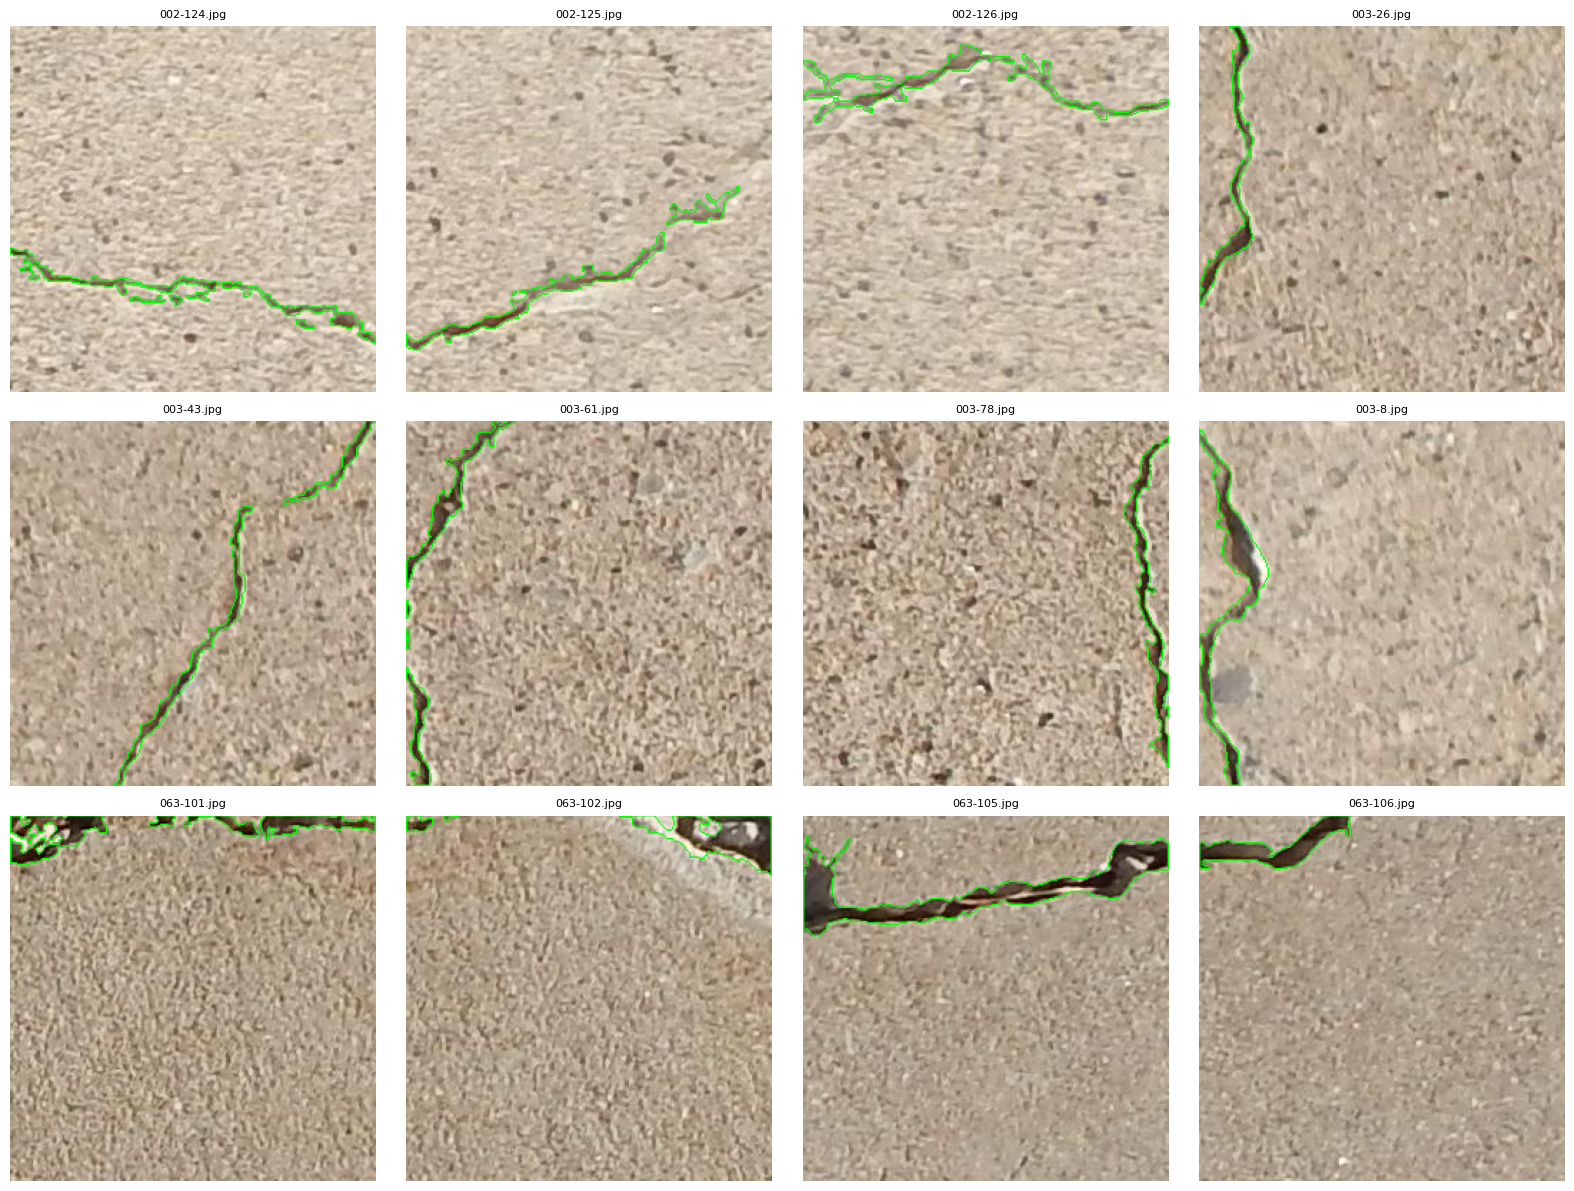

In [12]:
# ===== CELDA A · Leer las máscaras hechas en Paint y revisarlas =====
from PIL import Image
from tqdm.auto import tqdm

CARPETA_ORIGINALES = Path('/content/drive/MyDrive/IA 2/imagenes a pintar')   # fotos SIN pintar
CARPETA_PINTADAS   = Path('/content/drive/MyDrive/IA 2/ya con mascara')      # lo que pintaron en Paint
CARPETA_SALIDA     = Path('/content/drive/MyDrive/IA 2/resultados_localizacion')
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)

UMBRAL_DECISION = globals().get('UMBRAL_DECISION', 0.512)   # solo marca la columna "detectada"; 0.512 = umbral F2 del entrenamiento
EXT = {'.jpg', '.jpeg', '.png', '.bmp'}

def _archivos(carpeta):
    return sorted(f for f in Path(carpeta).iterdir() if f.is_file() and f.suffix.lower() in EXT)

def _leer_original(ruta):
    im = Image.open(ruta).convert('RGB')
    if im.size != (TAM_IMG[1], TAM_IMG[0]):
        im = im.resize((TAM_IMG[1], TAM_IMG[0]), Image.BILINEAR)
    return np.array(im)

def _leer_pintada(ruta, forma):
    im = Image.open(ruta).convert('RGB')
    if im.size != (forma[1], forma[0]):
        im = im.resize((forma[1], forma[0]), Image.NEAREST)     # NEAREST: no inventa colores nuevos
    return np.array(im)

def extraer_mascara(pintada, original, umbral_dif=60):
    """
    Convierte lo que pintaste en una máscara 0/1, sin importar el color del pincel.
      · Si el archivo es una máscara blanco/negro, la grieta es el color minoritario.
      · Si es la foto con la grieta pintada encima, la máscara son los píxeles que CAMBIARON respecto a la original.
    """
    g = cv2.cvtColor(pintada, cv2.COLOR_RGB2GRAY)
    if ((g < 30) | (g > 225)).mean() > 0.97:                    # lienzo casi solo blanco y negro
        blanco = g > 127
        mascara, modo = (blanco if blanco.mean() < 0.5 else ~blanco), 'binaria'
    else:
        dif = np.abs(pintada.astype(np.int16) - original.astype(np.int16)).max(axis=2)
        mascara, modo = dif > umbral_dif, 'diferencia'
    mascara = mascara.astype(np.uint8)
    n, et, st, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)   # quita motas sueltas (ruido JPG)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] < 5:
            mascara[et == i] = 0
    return mascara, modo

# ---- emparejar cada imagen original con su archivo pintado (mismo nombre; tolera mayúsculas y sufijos) ----
pintadas = {f.stem.lower(): f for f in _archivos(CARPETA_PINTADAS)}
def _buscar(stem):
    s = stem.lower()
    if s in pintadas:
        return pintadas[s]
    cand = [f for k, f in pintadas.items() if k.startswith(s) or s.startswith(k)]
    return cand[0] if len(cand) == 1 else None

datos, sin_par, problemas = [], [], []
for f in _archivos(CARPETA_ORIGINALES):
    p = _buscar(f.stem)
    if p is None:
        sin_par.append(f.name); continue
    orig = _leer_original(f)
    mascara, modo = extraer_mascara(_leer_pintada(p, orig.shape[:2]), orig)
    frac = mascara.mean()
    if mascara.sum() < 20:
        problemas.append((f.name, 'máscara vacía: no se detectó nada pintado')); continue
    if frac > 0.25:
        problemas.append((f.name, f'máscara enorme ({100*frac:.0f} % de la imagen): ¿se pintó fondo o se cambió la imagen?')); continue
    datos.append({'nombre': f.name, 'img': orig, 'mask': mascara, 'modo': modo})

print(f'Originales: {len(_archivos(CARPETA_ORIGINALES))} | pintadas: {len(pintadas)} | pares válidos: {len(datos)}')
print('Modo de lectura:', pd.Series([d["modo"] for d in datos]).value_counts().to_dict())
print(f'Grosor medio de la máscara: {np.mean([d["mask"].mean() for d in datos])*100:.2f} % de la imagen')
if sin_par:   print(f'\n⚠️ Originales SIN archivo pintado ({len(sin_par)}):', sin_par[:10], '...' if len(sin_par) > 10 else '')
if problemas: print('\n⚠️ Descartadas:'); [print('  ', n, '->', m) for n, m in problemas]

# ---- guardar las máscaras como PNG binario (0/255) para el repositorio / el equipo ----
dir_bin = CARPETA_SALIDA / 'mascaras_binarias'; dir_bin.mkdir(exist_ok=True)
for d in datos:
    cv2.imwrite(str(dir_bin / (Path(d['nombre']).stem + '.png')), d['mask'] * 255)

# ---- REVISIÓN VISUAL: el contorno verde debe quedar sobre la grieta ----
def revisar_mascaras(datos, n=12, columnas=4):
    n = min(n, len(datos)); filas_ = int(np.ceil(n / columnas))
    fig, ejes = plt.subplots(filas_, columnas, figsize=(4 * columnas, 4 * filas_))
    for eje, d in zip(np.atleast_1d(ejes).ravel(), datos[:n]):
        vista = d['img'].copy()
        cont, _ = cv2.findContours(d['mask'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(vista, cont, -1, (0, 255, 0), 1)
        eje.imshow(vista); eje.set_title(d['nombre'], fontsize=8)
    for eje in np.atleast_1d(ejes).ravel(): eje.axis('off')
    plt.tight_layout(); plt.show()
revisar_mascaras(datos)

In [13]:
# ===== CELDA B · Medir la localización (con y sin crestas) =====
def calcular_mapas(datos, modelo, tta=None):
    """Calcula el Grad-CAM UNA vez por imagen; la versión con crestas se obtiene refinando ese mismo mapa."""
    mapas = []
    for d in tqdm(datos, desc='Grad-CAM'):
        fusion, _, prob = cam_fusionada(d['img'], modelo, tta=tta, crestas=False)
        mapas.append({'sin crestas': fusion, 'con crestas': refinar_con_crestas(fusion, d['img']), 'prob': prob})
    return mapas

def metricas_localizacion(datos, mapas, variante, umbral_cam=0.5, dilatar_gt=9):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (dilatar_gt, dilatar_gt))
    filas = []
    for d, m in zip(datos, mapas):
        gt = cv2.dilate(d['mask'], k).astype(bool)            # se dilata porque la grieta es una línea de pocos píxeles
        pred = binarizar(m[variante], umbral_cam).astype(bool)
        inter = (pred & gt).sum()
        pico = np.unravel_index(m[variante].argmax(), m[variante].shape)
        filas.append({'imagen': d['nombre'], 'prob': round(m['prob'], 3), 'detectada': m['prob'] >= UMBRAL_DECISION,
                      'punto_max_en_grieta': float(gt[pico]),
                      'cobertura': inter / gt.sum(),                              # % de la grieta (dilatada) que cubre la máscara
                      'precisión_pix': inter / pred.sum() if pred.sum() else 0.0, # % de la máscara que cae sobre la grieta
                      'IoU': inter / (pred | gt).sum(),
                      'Dice': 2 * inter / (pred.sum() + gt.sum()),
                      'área_pred_%': 100 * pred.mean()})
    return pd.DataFrame(filas)

COLS = ['punto_max_en_grieta', 'cobertura', 'precisión_pix', 'IoU', 'Dice', 'área_pred_%']

mapas = calcular_mapas(datos, modelo)

# --- resultado principal: umbral_cam = 0.5, GT dilatada 9 px ---
res = {v: metricas_localizacion(datos, mapas, v) for v in ('sin crestas', 'con crestas')}
resumen = pd.DataFrame({v: r[COLS].mean() for v, r in res.items()}).round(3)
print(f'Localización sobre {len(datos)} imágenes con grieta (umbral_cam = 0.5, GT dilatada 9 px)')
display(resumen)

det = pd.DataFrame({v: r[r.detectada][COLS].mean() for v, r in res.items()}).round(3)
print(f'Solo las {int(res["con crestas"].detectada.sum())} imágenes que el clasificador marca como grieta (P ≥ {UMBRAL_DECISION:.3f}):')
display(det)

# --- sensibilidad: ¿cambia la conclusión si se mueve el umbral del mapa o la dilatación? ---
barrido = []
for u in (0.3, 0.4, 0.5, 0.6):
    for dil in (1, 9):
        for v in ('sin crestas', 'con crestas'):
            r = metricas_localizacion(datos, mapas, v, umbral_cam=u, dilatar_gt=dil)
            barrido.append({'umbral_cam': u, 'dilatación GT': dil, 'variante': v, **r[COLS].mean().round(3).to_dict()})
display(pd.DataFrame(barrido).set_index(['umbral_cam', 'dilatación GT', 'variante'])[['punto_max_en_grieta', 'cobertura', 'IoU', 'Dice']])

# --- guardar para la presentación ---
res['con crestas'].to_csv(CARPETA_SALIDA / 'localizacion_con_crestas.csv', index=False, encoding='utf-8-sig')
res['sin crestas'].to_csv(CARPETA_SALIDA / 'localizacion_sin_crestas.csv', index=False, encoding='utf-8-sig')
resumen.to_csv(CARPETA_SALIDA / 'localizacion_resumen.csv', encoding='utf-8-sig')
print('Guardado en', CARPETA_SALIDA)

Grad-CAM:   0%|          | 0/50 [00:00<?, ?it/s]

Localización sobre 50 imágenes con grieta (umbral_cam = 0.5, GT dilatada 9 px)


,sin crestas,con crestas
punto_max_en_grieta,0.860,0.960
cobertura,0.485,0.250
precisión_pix,0.583,0.896
IoU,0.346,0.238
Dice,0.501,0.368
área_pred_%,5.566,2.057


Solo las 49 imágenes que el clasificador marca como grieta (P ≥ 0.512):


,sin crestas,con crestas
punto_max_en_grieta,0.878,0.980
cobertura,0.491,0.254
precisión_pix,0.591,0.911
IoU,0.351,0.243
Dice,0.508,0.374
área_pred_%,5.632,2.091


punto_max_en_grieta  cobertura    IoU  \
umbral_cam dilatación GT variante                                             
0.3        1             sin crestas                 0.46      0.760  0.175   
                         con crestas                 0.70      0.688  0.337   
           9             sin crestas                 0.86      0.736  0.350   
                         con crestas                 0.96      0.513  0.406   
0.4        1             sin crestas                 0.46      0.643  0.202   
                         con crestas                 0.70      0.555  0.361   
           9             sin crestas                 0.86      0.613  0.371   
                         con crestas                 0.96      0.365  0.327   
0.5        1             sin crestas                 0.46      0.515  0.201   
                         con crestas                 0.70      0.416  0.321   
           9             sin crestas                 0.86      0.485  0.346   
                         con crestas                 0.96      0.250  0.238   
0.6        1             sin crestas                 0.46      0.391  0.189   
                         con crestas                 0.70      0.293  0.252   
           9             sin crestas                 0.86      0.358  0.295   
                         con crestas                 0.96      0.166  0.164   

                                       Dice  
umbral_cam dilatación GT variante            
0.3        1             sin crestas  0.282  
                         con crestas  0.487  
           9             sin crestas  0.506  
                         con crestas  0.563  
0.4        1             sin crestas  0.318  
                         con crestas  0.515  
           9             sin crestas  0.529  
                         con crestas  0.476  
0.5        1             sin crestas  0.322  
                         con crestas  0.468  
           9             sin crestas  0.501  
                         con crestas  0.368  
0.6        1             sin crestas  0.308  
                         con crestas  0.383  
           9             sin crestas  0.440  
                         con crestas  0.267

Guardado en /content/drive/MyDrive/IA 2/resultados_localizacion


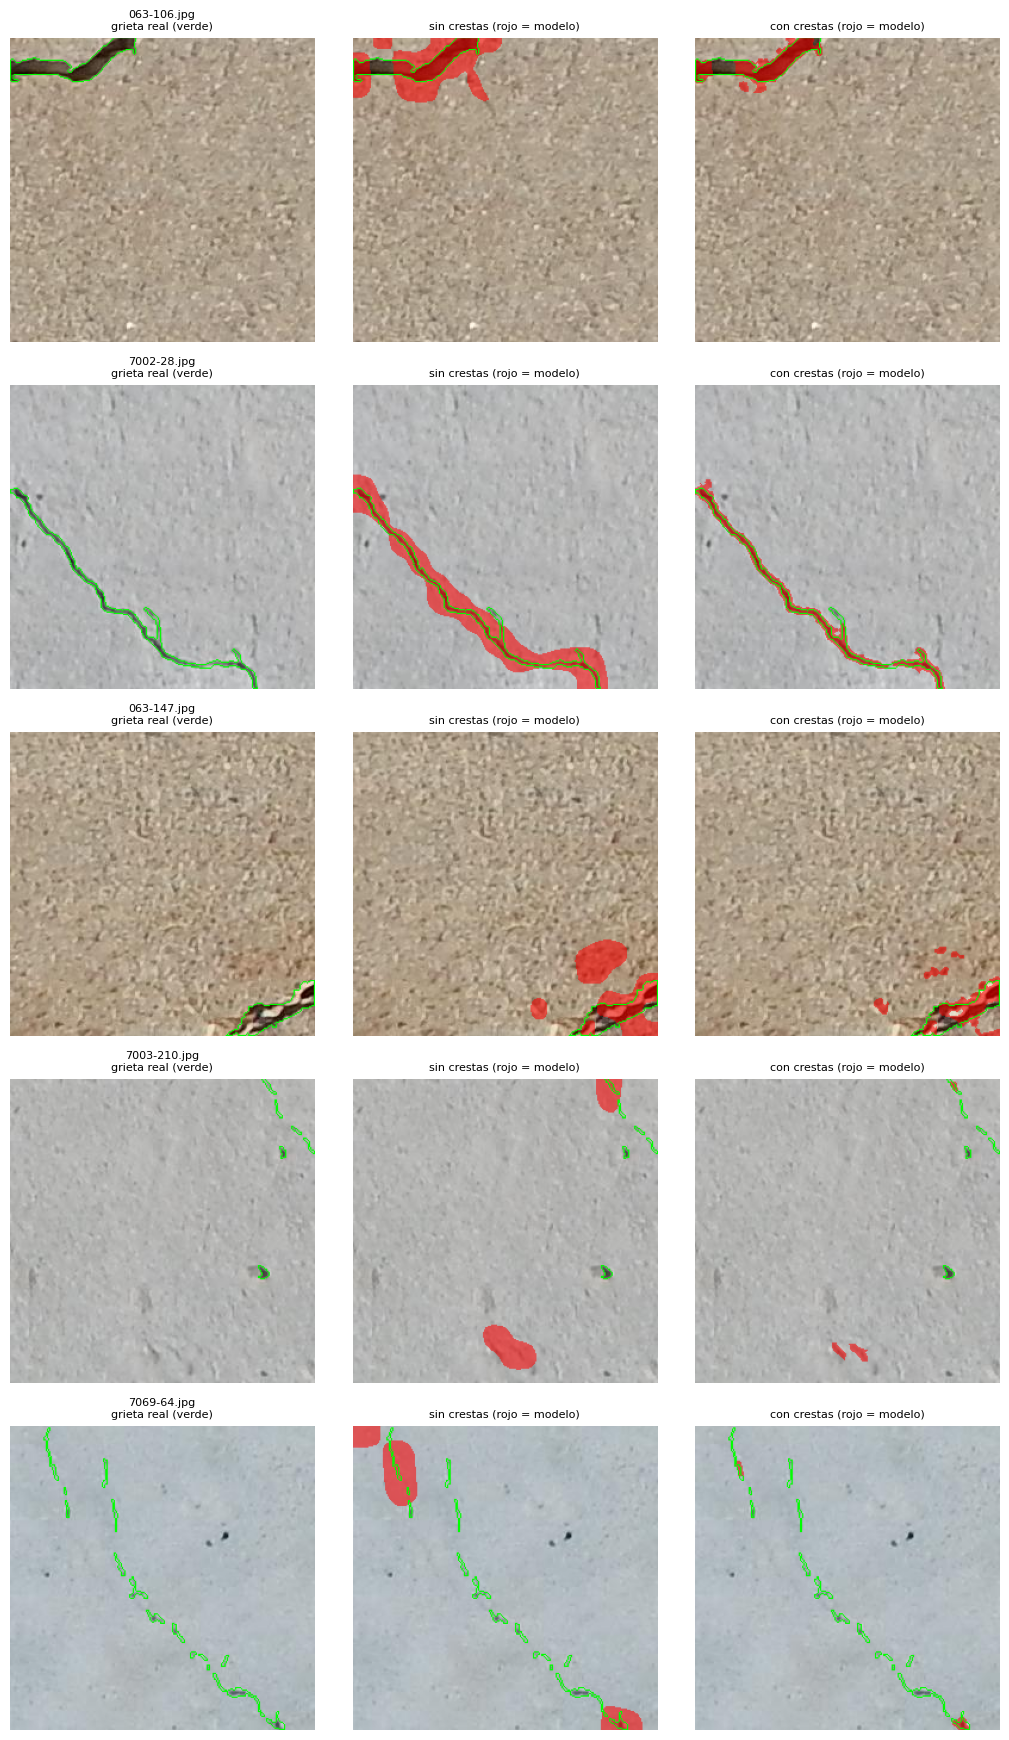

In [14]:
# ===== CELDA C · Figura para la diapositiva: grieta real vs. lo que marca el modelo =====
def figura_comparacion(datos, mapas, indices, umbral_cam=0.5, archivo=None):
    fig, ejes = plt.subplots(len(indices), 3, figsize=(10.5, 3.5 * len(indices)))
    ejes = np.atleast_2d(ejes)
    for fila, i in zip(ejes, indices):
        d, m = datos[i], mapas[i]
        cont_gt, _ = cv2.findContours(d['mask'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        vista = d['img'].copy(); cv2.drawContours(vista, cont_gt, -1, (0, 255, 0), 1)
        fila[0].imshow(vista); fila[0].set_title(f"{d['nombre']}\ngrieta real (verde)", fontsize=8)
        for eje, v in zip(fila[1:], ('sin crestas', 'con crestas')):
            pred = binarizar(m[v], umbral_cam)
            vista = pintar_resultado(d['img'], pred, [])
            cv2.drawContours(vista, cont_gt, -1, (0, 255, 0), 1)
            eje.imshow(vista); eje.set_title(f'{v} (rojo = modelo)', fontsize=8)
        for eje in fila: eje.axis('off')
    plt.tight_layout()
    if archivo: plt.savefig(archivo, dpi=200, bbox_inches='tight')
    plt.show()

r = res['con crestas'].reset_index(drop=True)
mejores = list(r.sort_values('cobertura', ascending=False).index[:3])
peores  = list(r.sort_values('cobertura').index[:2])
figura_comparacion(datos, mapas, mejores + peores, archivo=CARPETA_SALIDA / 'figura_localizacion.png')

,umbral elegido con,variante,umbral_cam,punto_max_en_grieta,cobertura,precisión_pix,IoU,Dice,área_pred_%
0,A,sin crestas,0.4,0.84,0.624,0.476,0.364,0.520,8.357
1,A,con crestas,0.2,0.92,0.698,0.491,0.397,0.553,10.035
2,B,sin crestas,0.4,0.88,0.602,0.530,0.379,0.537,8.427
3,B,con crestas,0.2,1.00,0.685,0.578,0.436,0.595,9.908


Promedio de las dos mitades (el umbral siempre se eligió con imágenes distintas a las que se midieron):


,punto_max_en_grieta,cobertura,precisión_pix,IoU,Dice,área_pred_%,umbral_cam
variante,,,,,,,
con crestas,0.96,0.692,0.534,0.416,0.574,9.971,0.2
sin crestas,0.86,0.613,0.503,0.372,0.528,8.392,0.4


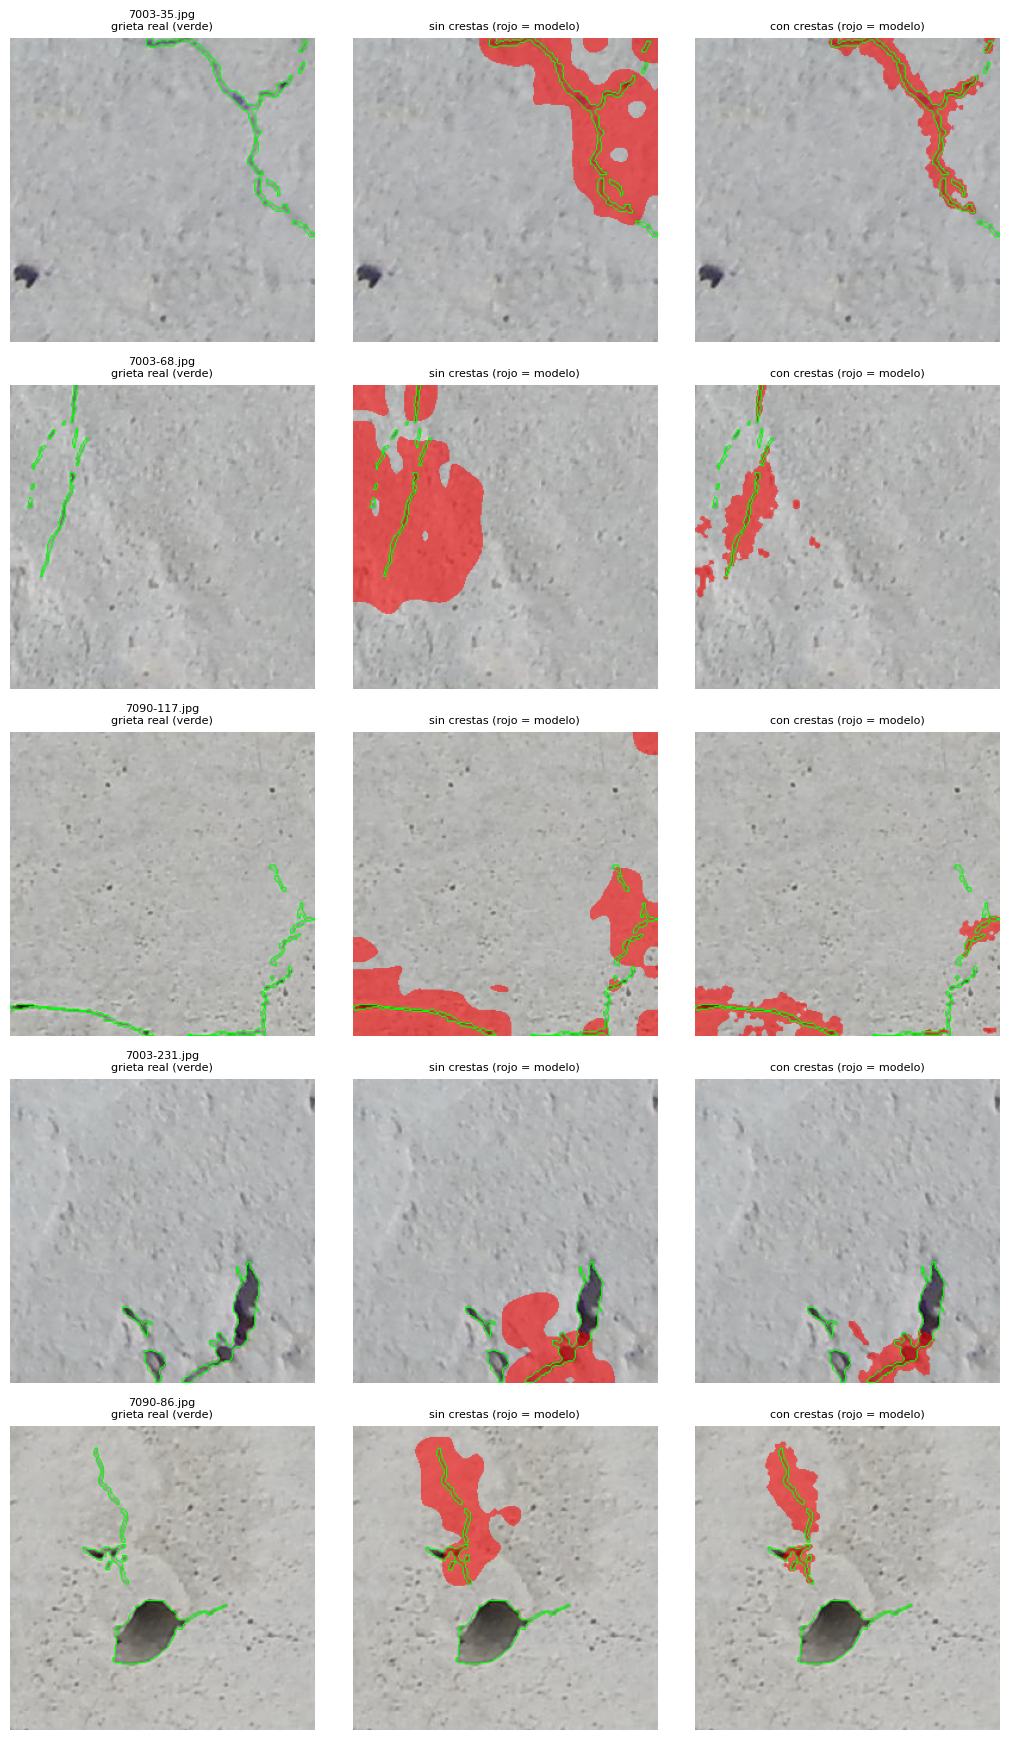

In [15]:
# ===== CELDA D · Elegir umbral_cam con una mitad de las imágenes y medir en la otra =====
rng = np.random.default_rng(123)
idx = rng.permutation(len(datos)); mitad = len(datos) // 2
partes = {'A': idx[:mitad], 'B': idx[mitad:]}
sub = lambda ids: ([datos[i] for i in ids], [mapas[i] for i in ids])

filas = []
for elige, mide in (('A', 'B'), ('B', 'A')):
    d_e, m_e = sub(partes[elige]); d_m, m_m = sub(partes[mide])
    for v in ('sin crestas', 'con crestas'):
        mejor = max((0.2, 0.3, 0.4, 0.5, 0.6), key=lambda u: metricas_localizacion(d_e, m_e, v, umbral_cam=u)['IoU'].mean())
        r = metricas_localizacion(d_m, m_m, v, umbral_cam=mejor)
        filas.append({'umbral elegido con': elige, 'variante': v, 'umbral_cam': mejor, **r[COLS].mean().round(3).to_dict()})
tabla_d = pd.DataFrame(filas)
display(tabla_d)
print('Promedio de las dos mitades (el umbral siempre se eligió con imágenes distintas a las que se midieron):')
display(tabla_d.groupby('variante')[COLS + ['umbral_cam']].mean().round(3))

# figura con el umbral ganador, 5 imágenes al azar (no solo las mejores y peores)
u_final = float(tabla_d[tabla_d.variante == 'con crestas'].umbral_cam.mean())
azar = list(np.random.default_rng(7).choice(len(datos), 5, replace=False))
figura_comparacion(datos, mapas, azar, umbral_cam=u_final, archivo=CARPETA_SALIDA / 'figura_localizacion_azar.png')